# 03 · Propensity model and segment value

> **Illustrative scenario.** The business framing is invented. The data is real (a UK online gift retailer, 2009-2011, with many wholesale buyers) and contains **no marketing contact data**. The outcome is ordering again within 90 days of a cutoff, not response to marketing.

**What this notebook does.** It presents the test results from frozen outputs: `outputs/metrics/results.json` (written by the test evaluation in `scripts/run_pipeline.py`; docs/METHODOLOGY.md section 6 says how often it was run) and the saved test-window predictions. **No model is refitted and no test metric is recomputed here.** The only new numbers are descriptive views of the frozen predictions (score deciles for the calibration plot).

**Design recap.** A 90-day repeat-purchase model is chosen on the val window (L2 logistic regression against a shallow gradient-boosted model), then retrained on the seasonal_2010, dev and val windows and scored on the test window (cutoff 2011-09-11).

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from segmentation_propensity import insights as ins
from segmentation_propensity import visualization as viz
from segmentation_propensity.utils import load_config, resolve

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
viz.apply_style()
cfg = load_config(Path("..") / "config.yaml")
FIG = resolve(cfg, "figures_dir")
res = ins.load_results(cfg)
R = res["by_id"]
prop_ctx = res["context"]["propensity"]
preds = pd.read_csv(resolve(cfg, "test_predictions_csv"))
names = {int(k): v for k, v in res["context"]["segmentation"]["names"].items()}
margin = cfg["evaluation"]["strong_margin"]
print(f"Test window: {len(preds):,} customers, {int(preds.y.sum()):,} repeat buyers ({preds.y.mean():.3f})")
print("Mode recorded at G2:", res["status"]["mode"])

Test window: 3,238 customers, 1,868 repeat buyers (0.577)
Mode recorded at G2: Findings


## 1. Choosing the logistic regularisation (dev window, 5-fold CV)
The C grid comes from the analysis plan. The selected C sits at the edge of the grid, but every C scores within a small fraction of one standard deviation of the others, so the choice barely matters. It matters even less because the gradient-boosted model was chosen on val (section 2).

Chosen C: 0.01 | spread of mean CV AUC across the grid: 0.0010 | typical fold SD: 0.024


,C,cv_auc_mean,cv_auc_sd
0,0.01,0.7750,0.0240
1,0.10,0.7746,0.0234
2,1.00,0.7741,0.0234
3,10.00,0.7739,0.0235


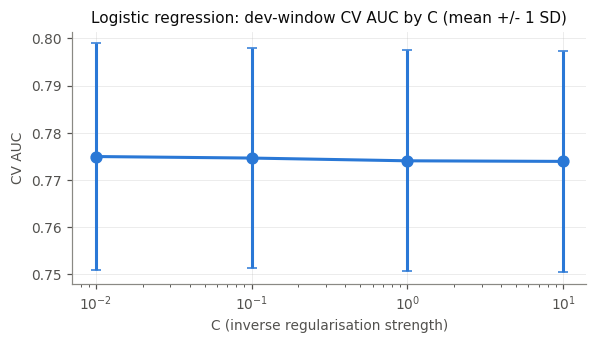

In [2]:
cv = pd.DataFrame(prop_ctx["cv"])
spread = cv.cv_auc_mean.max() - cv.cv_auc_mean.min()
print(f"Chosen C: {prop_ctx['C']} | spread of mean CV AUC across the grid: {spread:.4f} | typical fold SD: {cv.cv_auc_sd.mean():.3f}")
fig = viz.plot_cv_grid(cv)
viz.save_figure(fig, FIG / "prop_cv_grid.png")
cv.round(4)

## 2. Model choice on the val window
The val window (cutoff 2011-06-13) is used for selection only. The plan's rule picks the higher val AUC.

Chosen: hist_gradient_boosting | retrained on: seasonal_2010, dev, val


,label,value,ci_low,ci_high,n,n_events
0,L2 logistic regression,0.7843,0.7695,0.7983,3905,1503
1,Gradient boosting (depth 3),0.7933,0.7791,0.8081,3905,1503


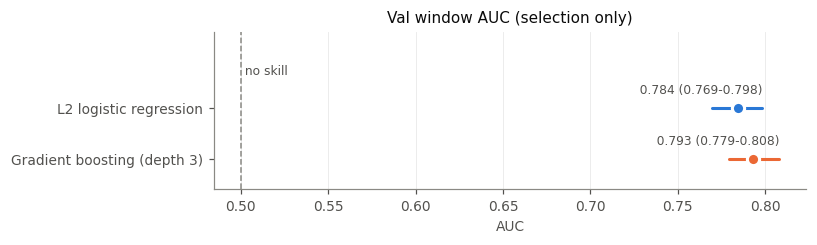

In [3]:
va = prop_ctx["val_auc"]
val_tab = pd.DataFrame([{"label": {"logistic": "L2 logistic regression", "hist_gradient_boosting": "Gradient boosting (depth 3)"}[k], **v} for k, v in va.items()])
fig = viz.plot_intervals(val_tab, "Val window AUC (selection only)", "AUC", references={"no skill": 0.5}, colors=viz.SERIES[:2])
viz.save_figure(fig, FIG / "prop_val_comparison.png")
print("Chosen:", prop_ctx["chosen"], "| retrained on:", ", ".join(prop_ctx["train_windows"]))
val_tab[["label", "value", "ci_low", "ci_high", "n", "n_events"]].round(4)

## 3. Test-window discrimination
All values are from `results.json`. The propensity model's minimum useful target (0.725) was set from the best segment-level AUC in an initial feasibility check that used this same window (docs/METHODOLOGY.md section 6). No paired test between the model and the segment scores was pre-declared, so none is reported, and no claim is made that the model ranks better than the segments or the rule.

P1 train AUC 0.804, test 0.755: gap 0.049 (overfit threshold 0.15)


,id,label,value,ci_low,ci_high,train_value,verdict,confidence
0,P1,Propensity model (gradient boosting),0.755,0.738,0.771,0.804,STRONG,High
1,S1_ref_rule,"RFM quintile rule, 3 groups",0.717,0.700,0.733,NaN,None,High
2,S1,"k-means segments, k=3",0.712,0.694,0.727,0.738,STRONG,High
3,S1_ref_recency,Recency only,0.685,0.666,0.703,NaN,None,High


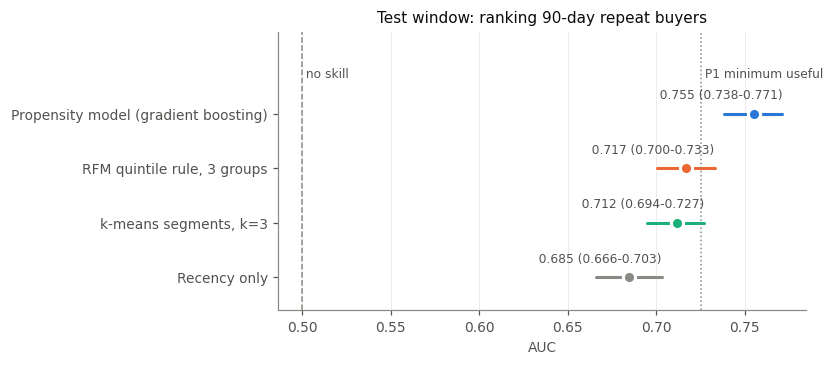

In [4]:
rows = [("P1", "Propensity model (gradient boosting)"), ("S1_ref_rule", "RFM quintile rule, 3 groups"),
        ("S1", "k-means segments, k=3"), ("S1_ref_recency", "Recency only")]
disc = pd.DataFrame([{"id": i, "label": lab, **{k: R[i][k] for k in ["value", "ci_low", "ci_high", "train_value", "verdict"]}} for i, lab in rows])
disc["confidence"] = [ins.confidence_label(r.value, r.ci_low, 0.5, margin) for r in disc.itertuples()]
fig = viz.plot_intervals(disc, "Test window: ranking 90-day repeat buyers", "AUC",
                         references={"no skill": 0.5, "P1 minimum useful": cfg["targets"]["P1_propensity_auc"]["minimum_useful"]},
                         colors=[viz.SERIES[0], viz.SERIES[1], viz.SERIES[2], viz.REFERENCE])
viz.save_figure(fig, FIG / "test_discrimination.png", dpi=300)
gap = res["status"]["P4_train_test_gap"]
print(f"P1 train AUC {R['P1']['train_value']:.3f}, test {R['P1']['value']:.3f}: gap {gap:.3f} (overfit threshold {cfg['evaluation']['overfit_gap']})")
disc.round(3)

## 4. Calibration (P2): failed, so scores are rankings only
P2 needs a calibration slope between 0.8 and 1.2 and a mean score within 0.03 of the observed rate. Both fail on the test window. The test label window runs from September to December, the seasonal peak, which is one plausible reason. Owner decision (2026-11-04): **use the model for ranking only**; no document states a probability or an expected number of buyers. The plot below groups the frozen test scores into deciles to show the pattern; the P2 numbers themselves come from `results.json`.

Slope 1.220 (target [0.8, 1.2]): FAIL
Mean score 0.620 vs observed rate 0.577: difference +0.043 (limit 0.03): FAIL


,bin,mean_score,observed_rate,n
0,0,0.326,0.228,324
1,1,0.423,0.377,324
2,2,0.472,0.410,324
3,3,0.528,0.461,323
4,4,0.580,0.478,324
5,5,0.636,0.611,324
6,6,0.696,0.672,323
7,7,0.761,0.728,324
8,8,0.838,0.827,324
9,9,0.942,0.975,324


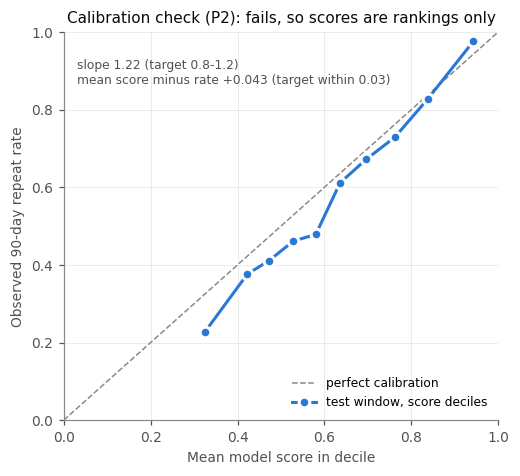

In [5]:
cal = res["calibration"]
rel = viz.reliability_table(preds.y, preds.p, n_bins=10)
fig = viz.plot_reliability(rel, cal["slope"], cal["calibration_in_the_large"])
viz.save_figure(fig, FIG / "prop_calibration.png", dpi=300)
p2 = cfg["targets"]["P2_calibration"]
print(f"Slope {cal['slope']:.3f} (target {p2['slope_range']}): {'pass' if res['status']['P2_slope_ok'] else 'FAIL'}")
print(f"Mean score {cal['mean_predicted']:.3f} vs observed rate {cal['event_rate']:.3f}: difference {cal['calibration_in_the_large']:+.3f} (limit {p2['max_abs_bias']}): {'pass' if res['status']['P2_bias_ok'] else 'FAIL'}")
rel.round(3)

Reading the plot: for customers in the lower and middle score deciles, the observed repeat rate sits below the score, while the top deciles are close to the diagonal. A slope above 1 summarises that pattern (observed rates rise more steeply than the scores), and the positive difference says scores run too high on average. Neither affects the order of customers, which is what P1 measures.

## 5. Brier skill (P3)
Brier skill compares squared error with always predicting the test-window repeat rate. It is positive, so the scores carry information, but with calibration failing this is not a licence to read them as probabilities.

In [6]:
p3 = R["P3"]
print(f"Brier skill {p3['value']:.3f} (95% CI {p3['ci_low']:.3f}-{p3['ci_high']:.3f}); no-skill value {p3['baseline_value']}")

Brier skill 0.183 (95% CI 0.163-0.203); no-skill value 0.0


## 6. Ranking customers within segments
Within-segment AUC asks: inside one frozen k-means segment, does the model still put repeat buyers ahead of non-buyers? These values were computed in the test evaluation and stored in `results.json`. Confidence labels use the G2 interval rules against chance (0.5); they are descriptive, not gate verdicts.

,label,share,test_repeat_rate,value,ci_low,ci_high,n,n_events,confidence
0,lapsed infrequent low-value,0.322,0.350,0.625,0.589,0.660,1044,365,Moderate
1,cooling regular mid-value,0.462,0.589,0.624,0.596,0.654,1495,880,Moderate
2,recent frequent high-value,0.216,0.891,0.750,0.699,0.798,699,623,High


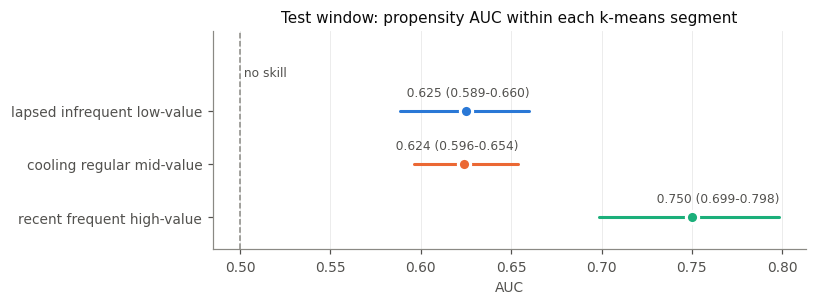

In [7]:
ws = pd.DataFrame([{"label": seg, **v} for seg, v in res["within_segment_propensity_auc"].items()])
ws["test_repeat_rate"] = ws.label.map(res["segment_test_rates"])
ws["share"] = ws.label.map(res["segment_test_shares"])
ws["confidence"] = [ins.confidence_label(r.value, r.ci_low, 0.5, margin) for r in ws.itertuples()]
fig = viz.plot_intervals(ws, "Test window: propensity AUC within each k-means segment", "AUC",
                         references={"no skill": 0.5}, colors=viz.SERIES[:3])
viz.save_figure(fig, FIG / "prop_within_segment.png")
ws[["label", "share", "test_repeat_rate", "value", "ci_low", "ci_high", "n", "n_events", "confidence"]].round(3)

## 7. Key findings for the checkpoint

In [8]:
p1, s1, rr = R["P1"], R["S1"], R["S1_ref_rule"]
findings = [
    f"Propensity model ranks 90-day repeat buyers well above chance on the test window: AUC {p1['value']:.3f} ({p1['ci_low']:.3f}-{p1['ci_high']:.3f}), verdict {p1['verdict']}; minimum useful {cfg['targets']['P1_propensity_auc']['minimum_useful']} met.",
    f"No overfit: train AUC {p1['train_value']:.3f}, gap {gap:.3f}.",
    f"Segment-level scores for comparison: RFM rule {rr['value']:.3f} ({rr['ci_low']:.3f}-{rr['ci_high']:.3f}), k-means {s1['value']:.3f} ({s1['ci_low']:.3f}-{s1['ci_high']:.3f}).",
    f"Calibration fails (slope {cal['slope']:.2f}, mean score {cal['calibration_in_the_large']:+.3f} above the observed rate): rankings only.",
    "Within-segment AUC: " + "; ".join(f"{r.label} {r.value:.3f} ({r.ci_low:.3f}-{r.ci_high:.3f}, {r.confidence})" for r in ws.itertuples()),
]
for f in findings:
    print("-", f)

- Propensity model ranks 90-day repeat buyers well above chance on the test window: AUC 0.755 (0.738-0.771), verdict STRONG; minimum useful 0.725 met.
- No overfit: train AUC 0.804, gap 0.049.
- Segment-level scores for comparison: RFM rule 0.717 (0.700-0.733), k-means 0.712 (0.694-0.727).
- Calibration fails (slope 1.22, mean score +0.043 above the observed rate): rankings only.
- Within-segment AUC: lapsed infrequent low-value 0.625 (0.589-0.660, Moderate); cooling regular mid-value 0.624 (0.596-0.654, Moderate); recent frequent high-value 0.750 (0.699-0.798, High)
